# Confidence analysis
## Setup — full test split, top-class confidence, no calibration fitting

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

threshold, n_bins = 0.99, 10
model_names = ['resnet18', 'vit']
class_names = list(json.loads(Path('data/metadata.json').read_text())['label'].values())
class_names[3] = 'immature granulocytes'
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    images, labels = data['test_images'], data['test_labels'].ravel()
probabilities = []
for name in model_names:
    rows = np.loadtxt(f'predictions/{name}_test.csv', delimiter=',', skiprows=1)
    np.testing.assert_array_equal(rows[:, 0], np.arange(len(labels)))
    np.testing.assert_array_equal(rows[:, 1], labels)
    probabilities.append(rows[:, 3:])
probabilities = np.stack(probabilities)
np.testing.assert_allclose(probabilities.sum(-1), 1, atol=1e-6)
predicted = probabilities.argmax(-1)
confidence = probabilities.max(-1)
correct = predicted == labels
bins = np.linspace(0, 1, n_bins + 1)
centers = (bins[:-1] + bins[1:]) / 2

def bin_ids(values):
    return np.clip(np.searchsorted(bins, values, side='right') - 1, 0, n_bins - 1)

def entropy(p):
    p = np.asarray(p, dtype=float)
    return -(p * np.log(np.maximum(p, 1e-300))).sum(-1) / np.log(p.shape[-1])

uncertainty = entropy(probabilities)
print(f'{len(labels)} test images; high-confidence threshold: {threshold:.0%}')

3421 test images; high-confidence threshold: 99%


## Reliability diagram — equal-width confidence bins; ECE weighted by bin counts; empty bins omitted

resnet18: accuracy=95.79%, mean confidence=98.71%, ECE=0.0302
vit: accuracy=96.99%, mean confidence=98.62%, ECE=0.0167


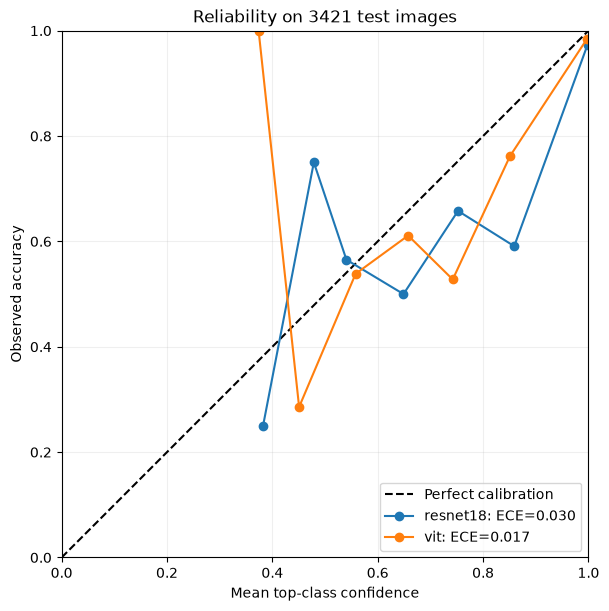

In [2]:
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for m, name in enumerate(model_names):
    groups = bin_ids(confidence[m])
    occupied = [groups == b for b in range(n_bins) if (groups == b).any()]
    x = np.array([confidence[m, mask].mean() for mask in occupied])
    y = np.array([correct[m, mask].mean() for mask in occupied])
    counts = np.array([mask.sum() for mask in occupied])
    ece = np.sum(counts * np.abs(y - x)) / len(labels)
    ax.plot(x, y, 'o-', label=f'{name}: ECE={ece:.3f}')
    print(f'{name}: accuracy={correct[m].mean():.2%}, mean confidence={confidence[m].mean():.2%}, ECE={ece:.4f}')
ax.set(xlabel='Mean top-class confidence', ylabel='Observed accuracy',
       title=f'Reliability on {len(labels)} test images', xlim=(0, 1), ylim=(0, 1))
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

## Confidence distributions — one stacked chart per model, for correct and incorrect images separately; stacks show true class

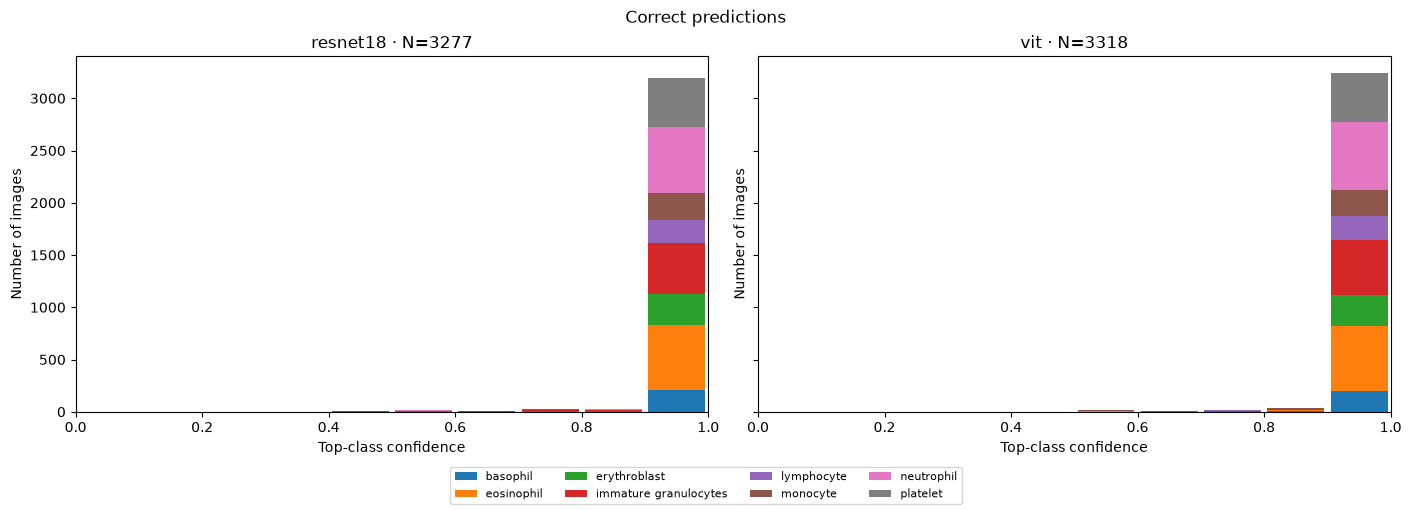

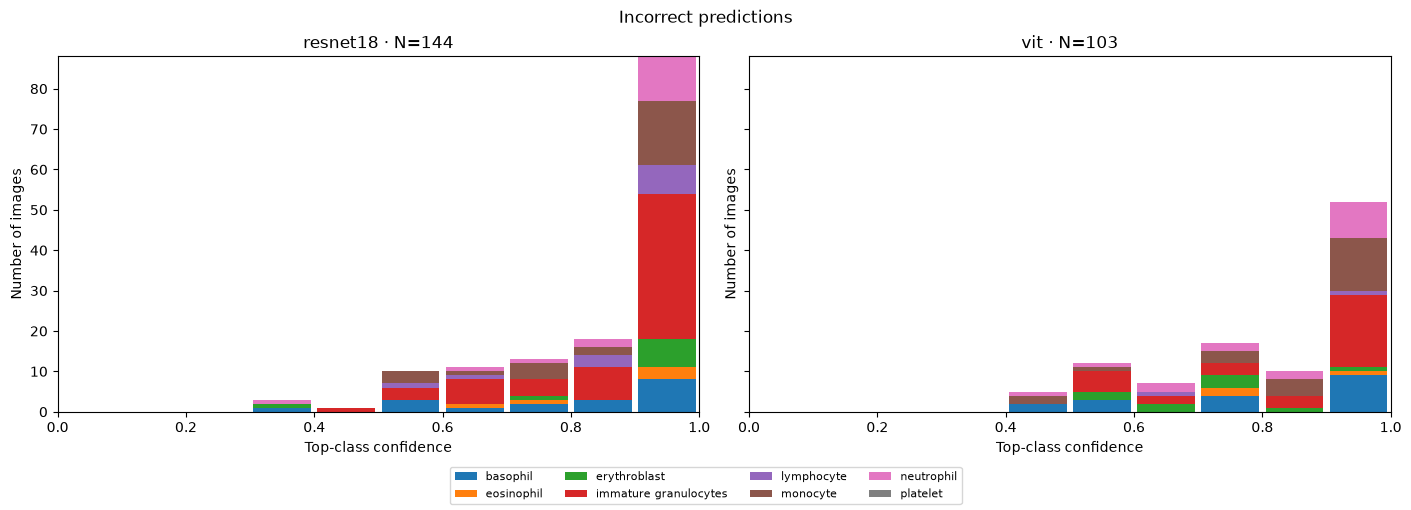

In [3]:
for is_correct, title in [(True, 'Correct predictions'), (False, 'Incorrect predictions')]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True, layout='constrained')
    for m, ax in enumerate(axes):
        bottom = np.zeros(n_bins)
        for c, class_name in enumerate(class_names):
            mask = (correct[m] == is_correct) & (labels == c)
            counts = np.histogram(confidence[m, mask], bins=bins)[0]
            ax.bar(centers, counts, width=0.09, bottom=bottom, color=f'C{c}', label=class_name)
            bottom += counts
        ax.set(title=f'{model_names[m]} · N={(correct[m] == is_correct).sum()}',
               xlabel='Top-class confidence', ylabel='Number of images', xlim=(0, 1))
    handles, names = axes[0].get_legend_handles_labels()
    fig.legend(handles, names, loc='outside lower center', ncol=4, fontsize=8)
    fig.suptitle(title)
    plt.show()

## Confidence disagreement — each model's own maximum probability, not necessarily the same class

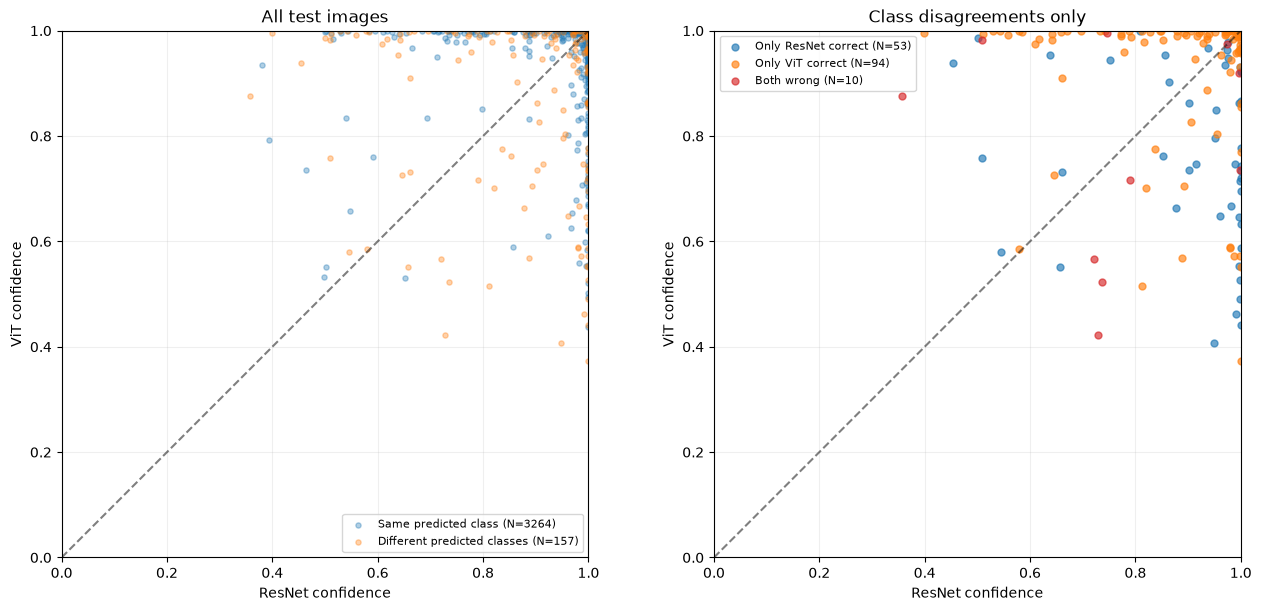

In [4]:
agree = predicted[0] == predicted[1]
fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout='constrained')
for mask, color, title in [(agree, 'C0', 'Same predicted class'), (~agree, 'C1', 'Different predicted classes')]:
    axes[0].scatter(confidence[0, mask], confidence[1, mask], s=14, alpha=0.35,
                    color=color, label=f'{title} (N={mask.sum()})')
groups = [(correct[0] & ~correct[1], 'C0', 'Only ResNet correct'),
          (~correct[0] & correct[1], 'C1', 'Only ViT correct'),
          (~correct[0] & ~correct[1], 'C3', 'Both wrong')]
for mask, color, title in groups:
    mask = mask & ~agree
    axes[1].scatter(confidence[0, mask], confidence[1, mask], s=25, alpha=0.65,
                    color=color, label=f'{title} (N={mask.sum()})')
for ax, title in zip(axes, ['All test images', 'Class disagreements only']):
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    ax.set(title=title, xlabel='ResNet confidence', ylabel='ViT confidence', xlim=(0, 1), ylim=(0, 1))
    ax.set_aspect('equal')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.show()

## Predictive entropy — normalized to [0, 1]; correct/error distributions and empirical error rate by entropy bin, with image counts

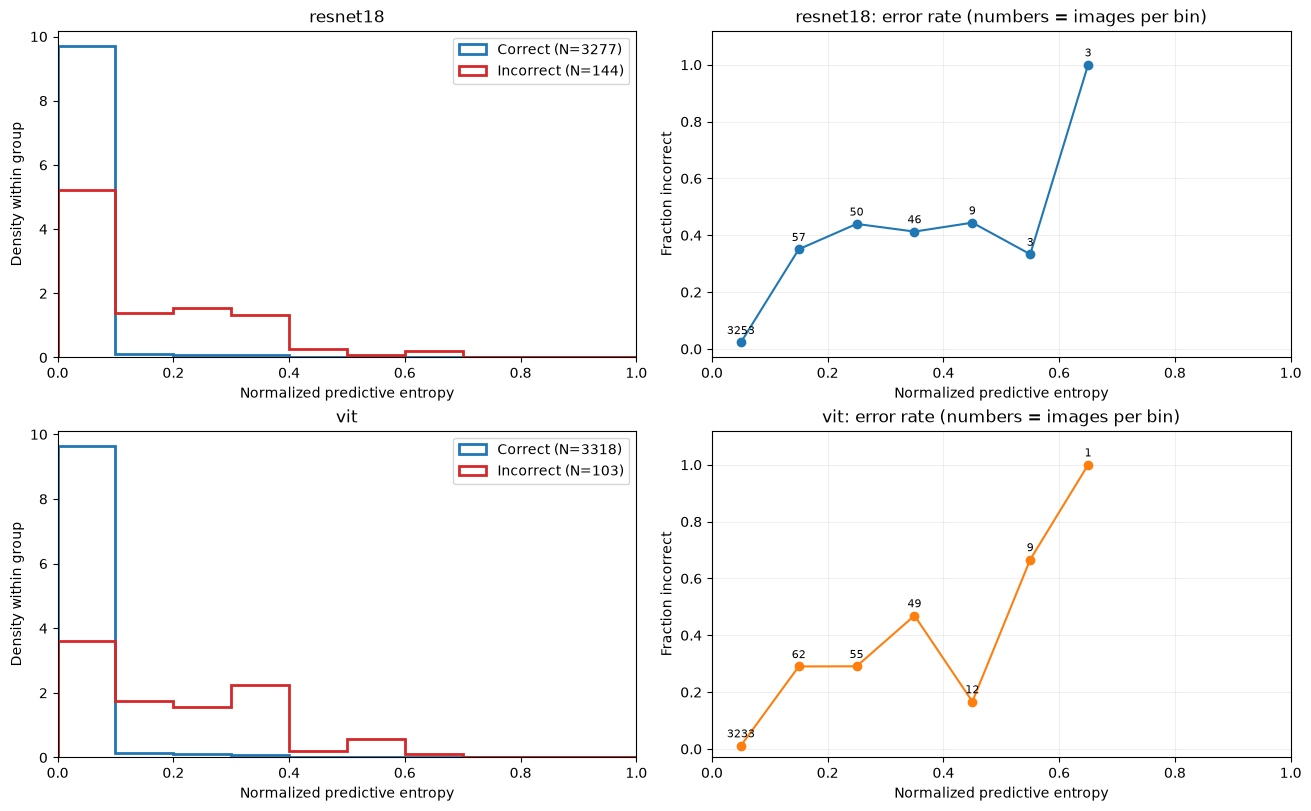

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
for m, name in enumerate(model_names):
    for mask, color, title in [(correct[m], 'C0', 'Correct'), (~correct[m], 'C3', 'Incorrect')]:
        if mask.any():
            axes[m, 0].hist(uncertainty[m, mask], bins=bins, density=True, histtype='step',
                            linewidth=2, color=color, label=f'{title} (N={mask.sum()})')
    axes[m, 0].set(title=name, xlabel='Normalized predictive entropy', ylabel='Density within group', xlim=(0, 1))
    axes[m, 0].legend()
    groups = bin_ids(uncertainty[m])
    counts = np.bincount(groups, minlength=n_bins)
    errors = np.bincount(groups, weights=~correct[m], minlength=n_bins)
    rates = np.divide(errors, counts, out=np.full(n_bins, np.nan), where=counts > 0)
    axes[m, 1].plot(centers, rates, 'o-', color=f'C{m}')
    for x, y, n in zip(centers, rates, counts):
        if n:
            axes[m, 1].annotate(str(n), (x, y), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8)
    axes[m, 1].set(title=f'{name}: error rate (numbers = images per bin)',
                   xlabel='Normalized predictive entropy', ylabel='Fraction incorrect', xlim=(0, 1), ylim=(-0.03, 1.12))
    axes[m, 1].grid(alpha=0.2)
plt.show()

## Confidence under transformations — same 320-image stability subset; average noise repeats within each image; dashed lines show baseline

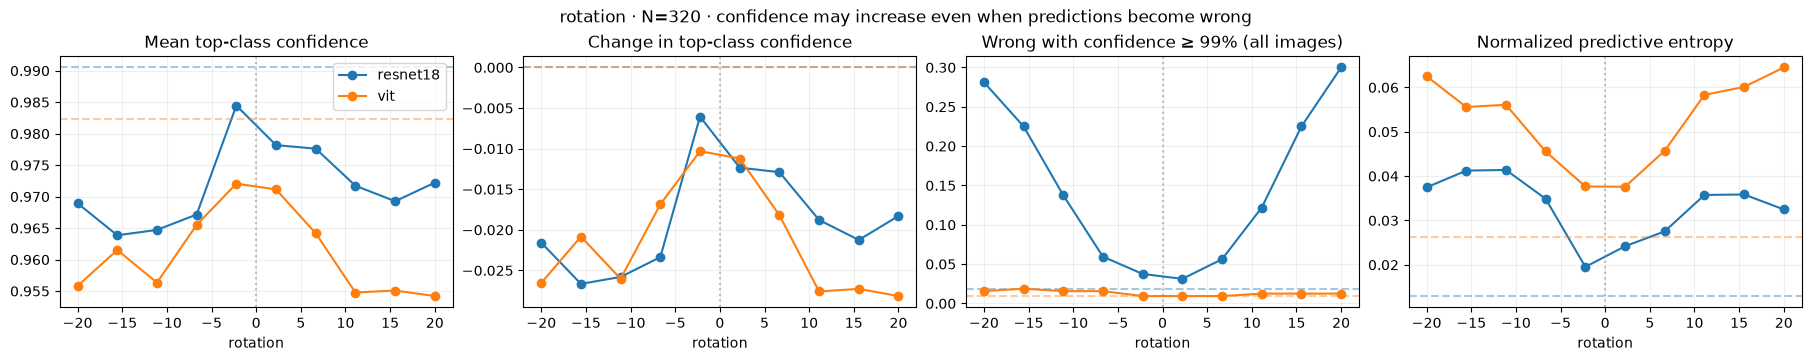

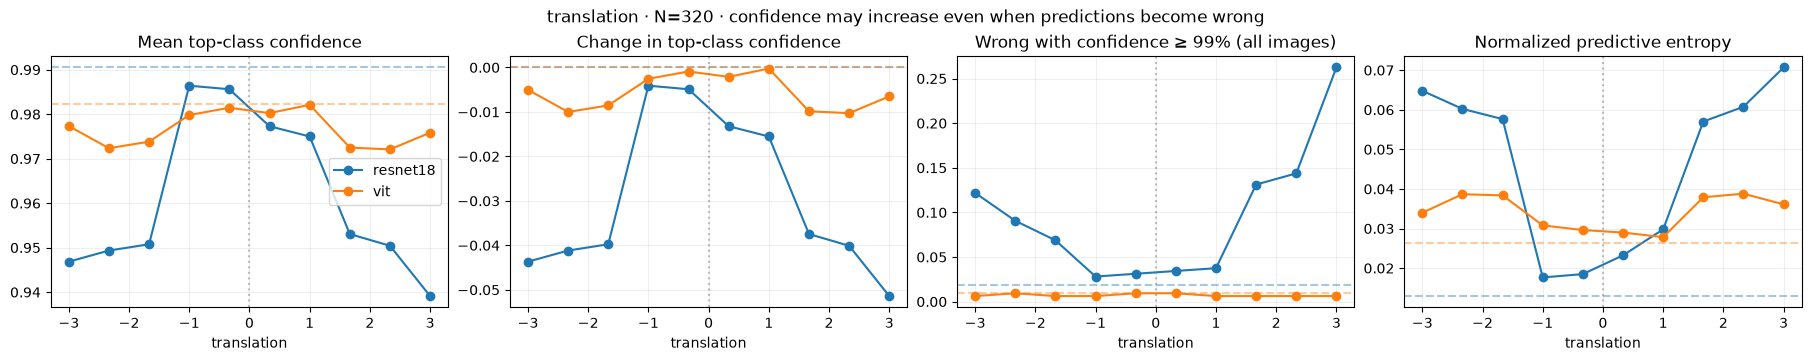

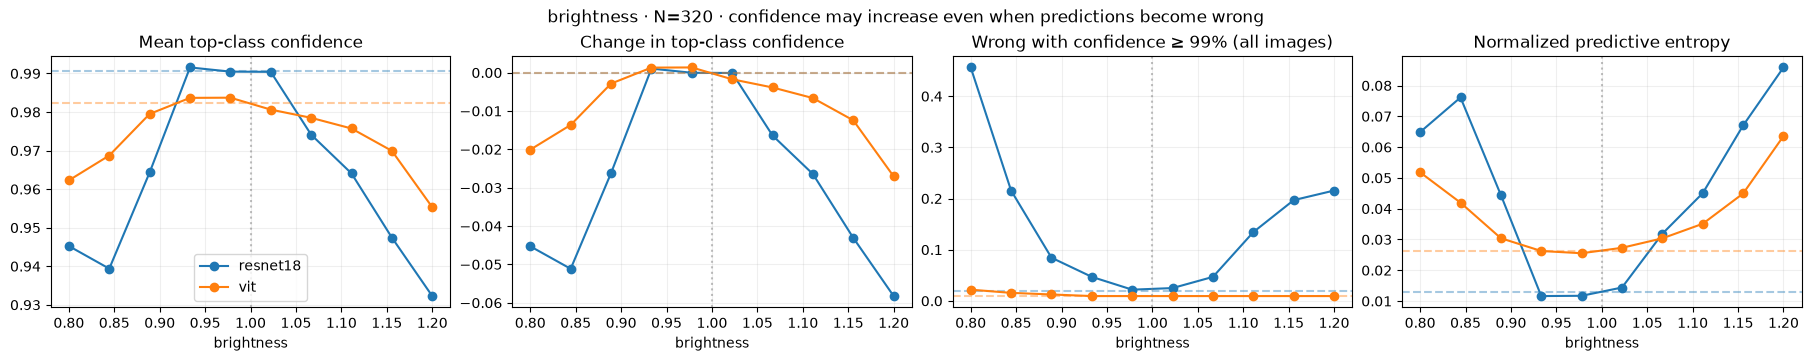

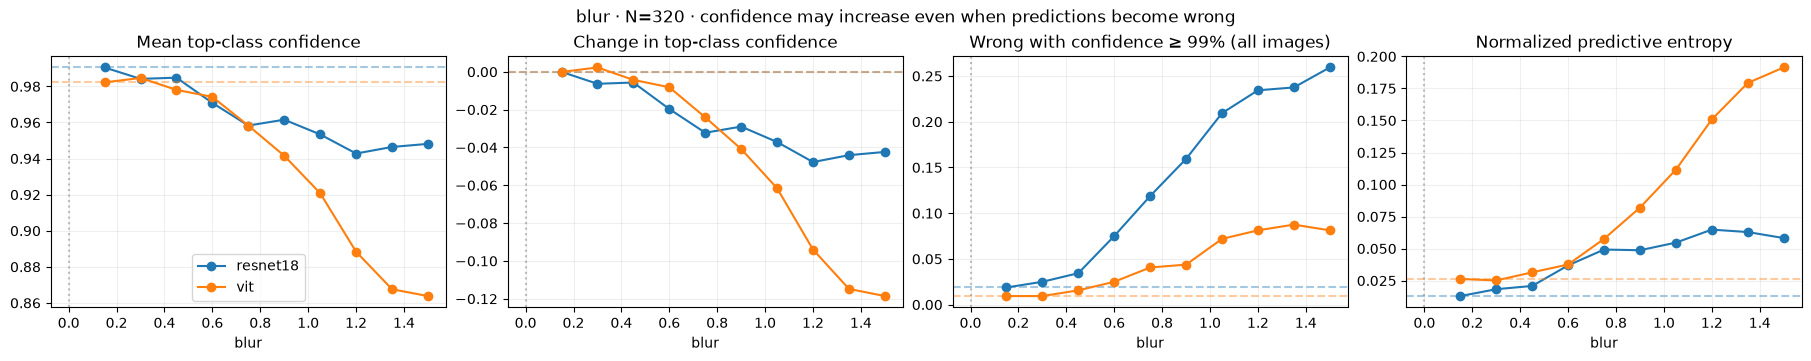

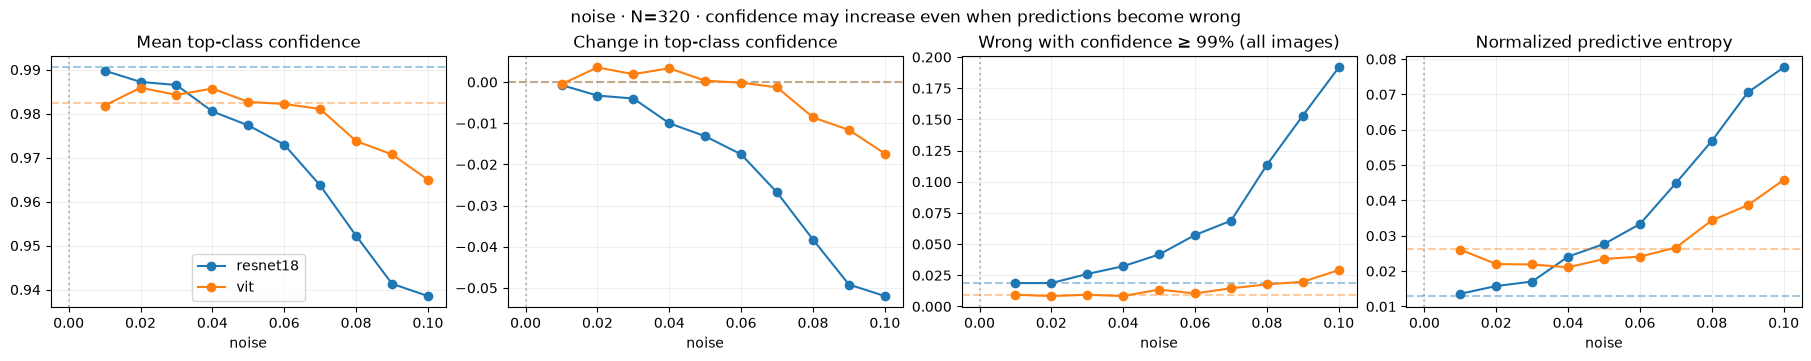

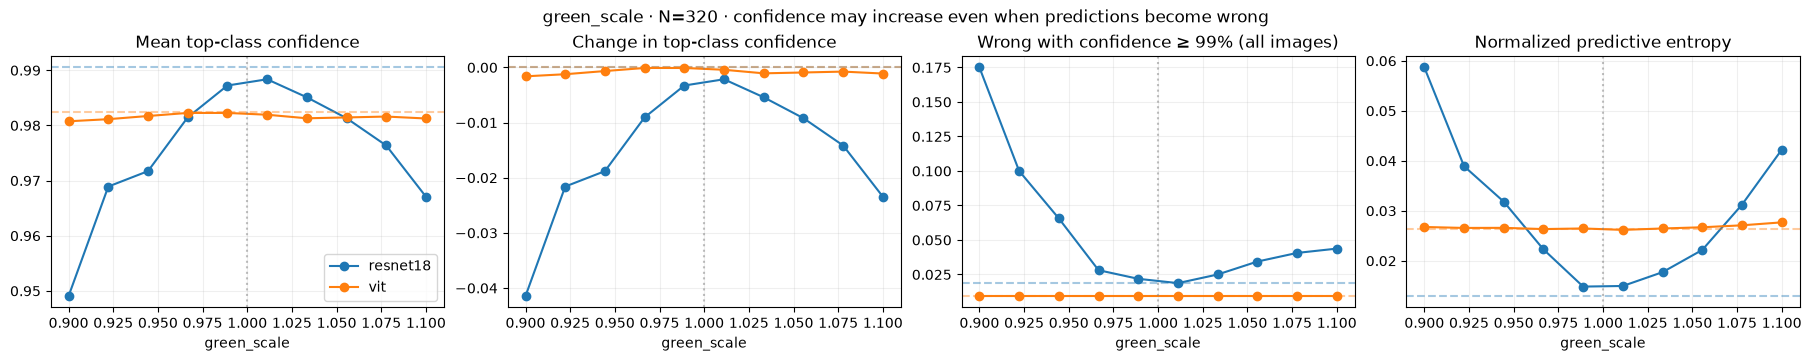

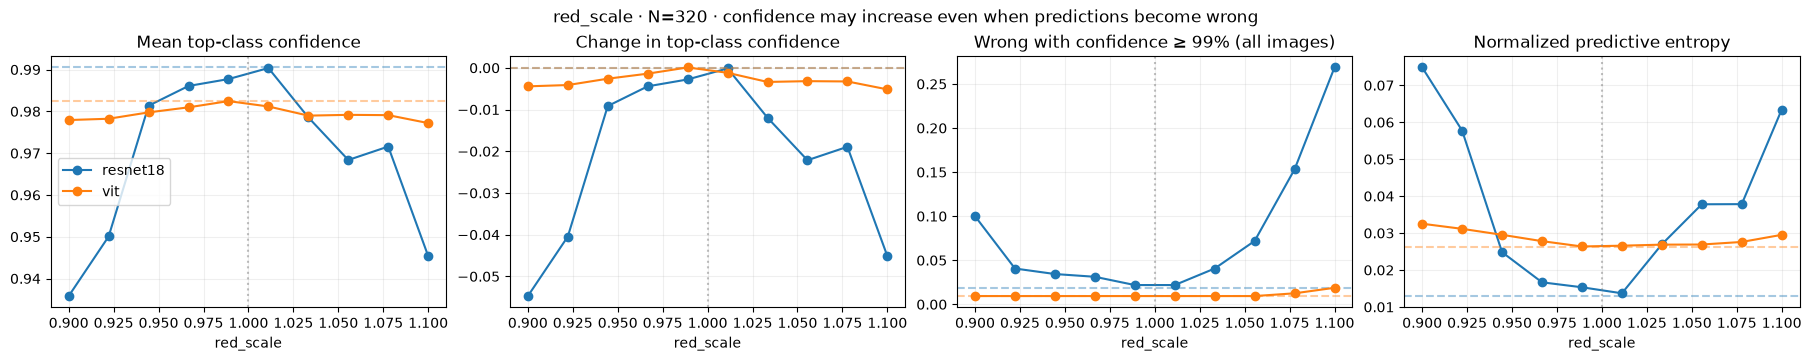

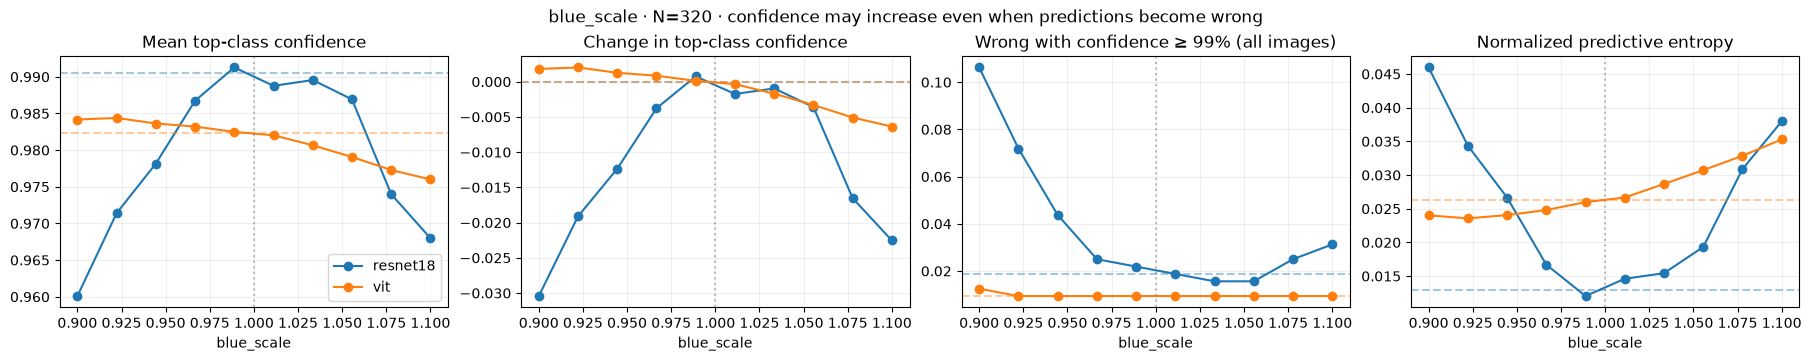

In [6]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['model_names'], model_names)
    indices, stability_labels = saved['indices'], saved['labels']
    baseline = saved['baseline']
    levels = {key[7:]: saved[key] for key in saved.files if key.startswith('levels_')}
    transformed = {kind: saved[kind] for kind in levels}
np.testing.assert_array_equal(stability_labels, labels[indices])
np.testing.assert_allclose(baseline, probabilities[:, indices], atol=1e-9)
base_confidence = baseline.max(-1)
base_entropy = entropy(baseline)
base_high_wrong = (baseline.argmax(-1) != stability_labels) & (base_confidence >= threshold)
confidence_changes = {}
for kind, p in transformed.items():
    conf = p.max(-1)
    high_wrong = (p.argmax(-1) != stability_labels) & (conf >= threshold)
    metrics = {
        'Mean top-class confidence': conf.mean(axis=2),
        'Change in top-class confidence': (conf - base_confidence[:, None, None, :]).mean(axis=2),
        f'Wrong with confidence ≥ {threshold:.0%} (all images)': high_wrong.mean(axis=2),
        'Normalized predictive entropy': entropy(p).mean(axis=2),
    }
    confidence_changes[kind] = metrics
    references = [base_confidence.mean(-1), np.zeros(2), base_high_wrong.mean(-1), base_entropy.mean(-1)]
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), layout='constrained')
    reference = 1 if kind.endswith('_scale') or kind == 'brightness' else 0
    for ax, (title, values), original in zip(axes, metrics.items(), references):
        for m, name in enumerate(model_names):
            line, = ax.plot(levels[kind], values[m].mean(-1), 'o-', label=name)
            ax.axhline(original[m], color=line.get_color(), ls='--', alpha=0.4)
        ax.axvline(reference, color='gray', ls=':', alpha=0.5)
        ax.set(title=title, xlabel=kind)
        ax.grid(alpha=0.2)
    axes[0].legend()
    fig.suptitle(f'{kind} · N={len(stability_labels)} · confidence may increase even when predictions become wrong')
    plt.show()

## Extract every high-confidence error — original RGB image, test index, labels, all probabilities, confidence and entropy; threshold editable above

In [7]:
high_confidence_wrong = {}
for m, name in enumerate(model_names):
    ids = np.flatnonzero(~correct[m] & (confidence[m] >= threshold))
    ids = ids[np.argsort(-confidence[m, ids], kind='stable')]
    high_confidence_wrong[name] = ids
    path = Path(f'predictions/high_confidence_wrong_{name}.npz')
    np.savez_compressed(path, images=images[ids], sample_index=ids, true_label=labels[ids],
                        predicted_label=predicted[m, ids], probabilities=probabilities[m, ids],
                        confidence=confidence[m, ids], normalized_entropy=uncertainty[m, ids],
                        class_names=class_names, model=name, split='test', threshold=threshold)
    print(f'{name}: {len(ids)} high-confidence errors → {path}')
    print('Test indices:', ids.tolist())

resnet18: 47 high-confidence errors → predictions\high_confidence_wrong_resnet18.npz
Test indices: [3126, 496, 1967, 1750, 3329, 340, 3373, 2908, 2935, 379, 2721, 2434, 3058, 1640, 1413, 3044, 2750, 476, 3235, 832, 849, 2942, 2251, 69, 516, 1688, 3035, 1130, 1018, 963, 873, 1629, 118, 35, 1555, 1259, 1542, 1546, 1765, 1125, 2310, 839, 271, 2917, 2036, 2735, 1108]
vit: 20 high-confidence errors → predictions\high_confidence_wrong_vit.npz
Test indices: [1462, 1750, 3126, 1629, 916, 1218, 576, 799, 476, 35, 1914, 290, 340, 432, 839, 3329, 148, 2982, 1575, 2086]


## Highest-confidence errors — first eight per model; class IDs follow data/metadata.json; all selected images are saved

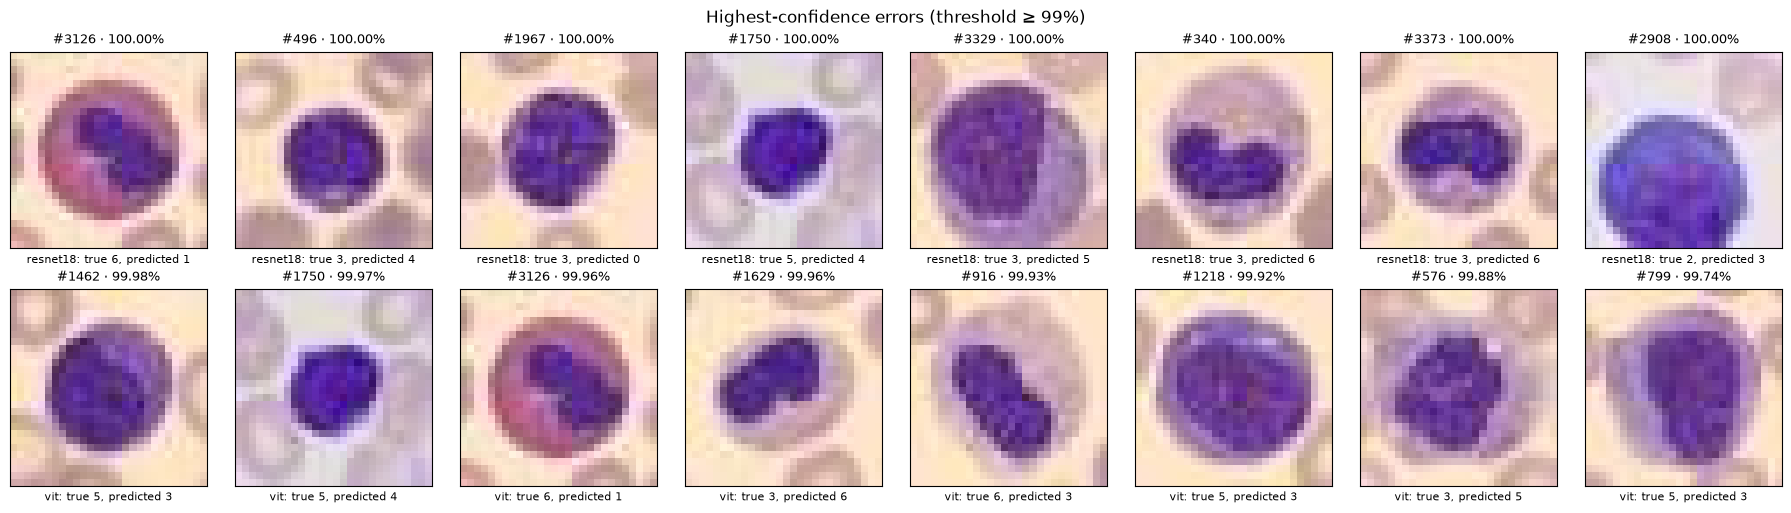

In [8]:
fig, axes = plt.subplots(2, 8, figsize=(18, 5), layout='constrained')
for m, name in enumerate(model_names):
    ids = high_confidence_wrong[name][:8]
    for ax in axes[m]:
        ax.axis('off')
    for ax, i in zip(axes[m], ids):
        ax.imshow(images[i])
        ax.set_title(f'#{i} · {confidence[m, i]:.2%}', fontsize=9)
        ax.set_xlabel(f'{name}: true {labels[i]}, predicted {predicted[m, i]}', fontsize=8)
        ax.axis('on')
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle(f'Highest-confidence errors (threshold ≥ {threshold:.0%})')
plt.show()

## High-confidence errors only — overlap percentages use each model's error count; Jaccard uses the union

Shared high-confidence errors: 8 test IDs: [35, 340, 476, 839, 1629, 1750, 3126, 3329]
resnet18: 8/47 shared (17.02%)
vit: 8/20 shared (40.00%)
Jaccard overlap: 13.56%
Same wrong class among shared errors: 100.00%


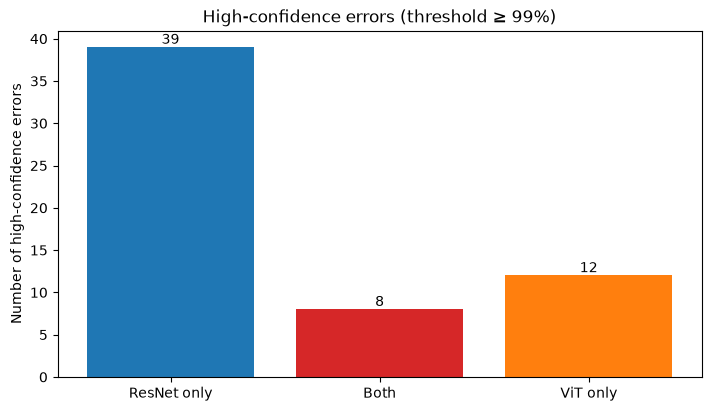

In [9]:
error_ids = [high_confidence_wrong[name] for name in model_names]
shared = np.intersect1d(*error_ids)
union = np.union1d(*error_ids)
print('Shared high-confidence errors:', len(shared), 'test IDs:', shared.tolist())
for name, ids in zip(model_names, error_ids):
    print(f'{name}: {len(shared)}/{len(ids)} shared ({len(shared) / len(ids):.2%})' if len(ids) else f'{name}: no high-confidence errors')
print(f'Jaccard overlap: {len(shared) / len(union):.2%}' if len(union) else 'Jaccard overlap: undefined')
if len(shared):
    print(f'Same wrong class among shared errors: {(predicted[0, shared] == predicted[1, shared]).mean():.2%}')
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
counts = [len(np.setdiff1d(error_ids[0], error_ids[1])), len(shared), len(np.setdiff1d(error_ids[1], error_ids[0]))]
ax.bar(['ResNet only', 'Both', 'ViT only'], counts, color=['C0', 'C3', 'C1'])
ax.bar_label(ax.containers[0])
ax.set(ylabel='Number of high-confidence errors', title=f'High-confidence errors (threshold ≥ {threshold:.0%})')
plt.show()

## True class → wrong predicted class — counts and percentages within each model's high-confidence errors, not class-specific error rates

resnet18: immature granulocytes → neutrophil: 10/47 (21.3%)
resnet18: neutrophil → immature granulocytes: 6/47 (12.8%)
resnet18: monocyte → immature granulocytes: 5/47 (10.6%)
resnet18: basophil → immature granulocytes: 4/47 (8.5%)
resnet18: immature granulocytes → monocyte: 4/47 (8.5%)
vit: neutrophil → immature granulocytes: 6/20 (30.0%)
vit: immature granulocytes → monocyte: 4/20 (20.0%)
vit: monocyte → immature granulocytes: 4/20 (20.0%)
vit: immature granulocytes → neutrophil: 2/20 (10.0%)
vit: basophil → immature granulocytes: 1/20 (5.0%)


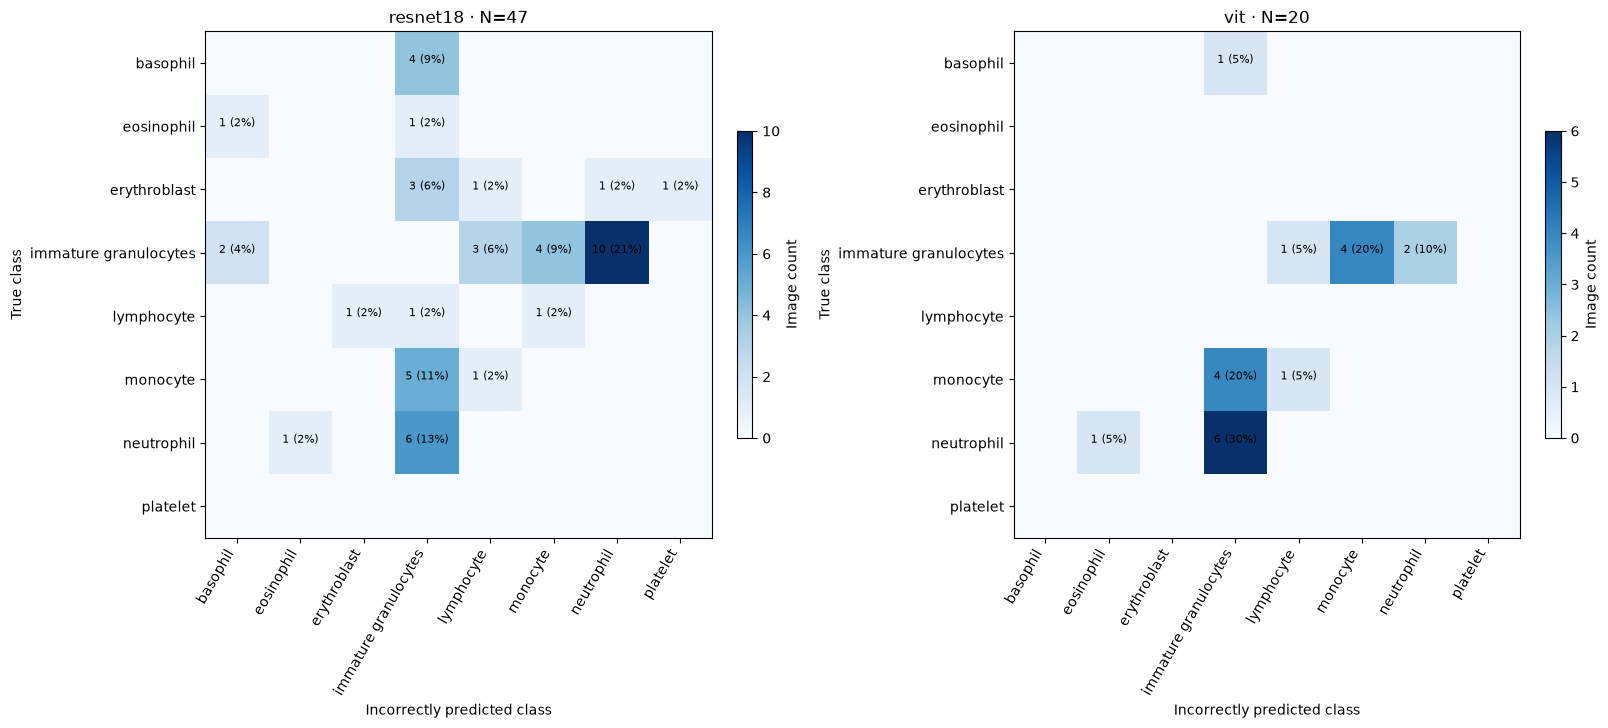

In [10]:
confusions, example_ids = [], []
fig, axes = plt.subplots(1, 2, figsize=(16, 7), layout='constrained')
for m, (ax, ids) in enumerate(zip(axes, error_ids)):
    matrix = np.zeros((8, 8), dtype=int)
    np.add.at(matrix, (labels[ids], predicted[m, ids]), 1)
    confusions.append(matrix)
    im = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(matrix.max(), 1))
    ax.set(title=f'{model_names[m]} · N={len(ids)}', xlabel='Incorrectly predicted class', ylabel='True class',
           xticks=range(8), xticklabels=class_names, yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for c, d in zip(*np.nonzero(matrix)):
        ax.text(d, c, f'{matrix[c, d]} ({matrix[c, d] / len(ids):.0%})', ha='center', fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.6, label='Image count')
    pairs = np.dstack(np.unravel_index(np.argsort(-matrix.ravel(), kind='stable'), matrix.shape))[0]
    pairs = [(c, d) for c, d in pairs if matrix[c, d] > 0]
    for c, d in pairs[:5]:
        print(f'{model_names[m]}: {class_names[c]} → {class_names[d]}: {matrix[c, d]}/{len(ids)} ({matrix[c, d] / len(ids):.1%})')
    example_ids.append(np.array([ids[np.flatnonzero((labels[ids] == c) & (predicted[m, ids] == d))[0]] for c, d in pairs[:3]], dtype=int))
plt.show()

## Simple RGB features — boundary gradient energy is only a proxy for edge content, not cell location or segmentation

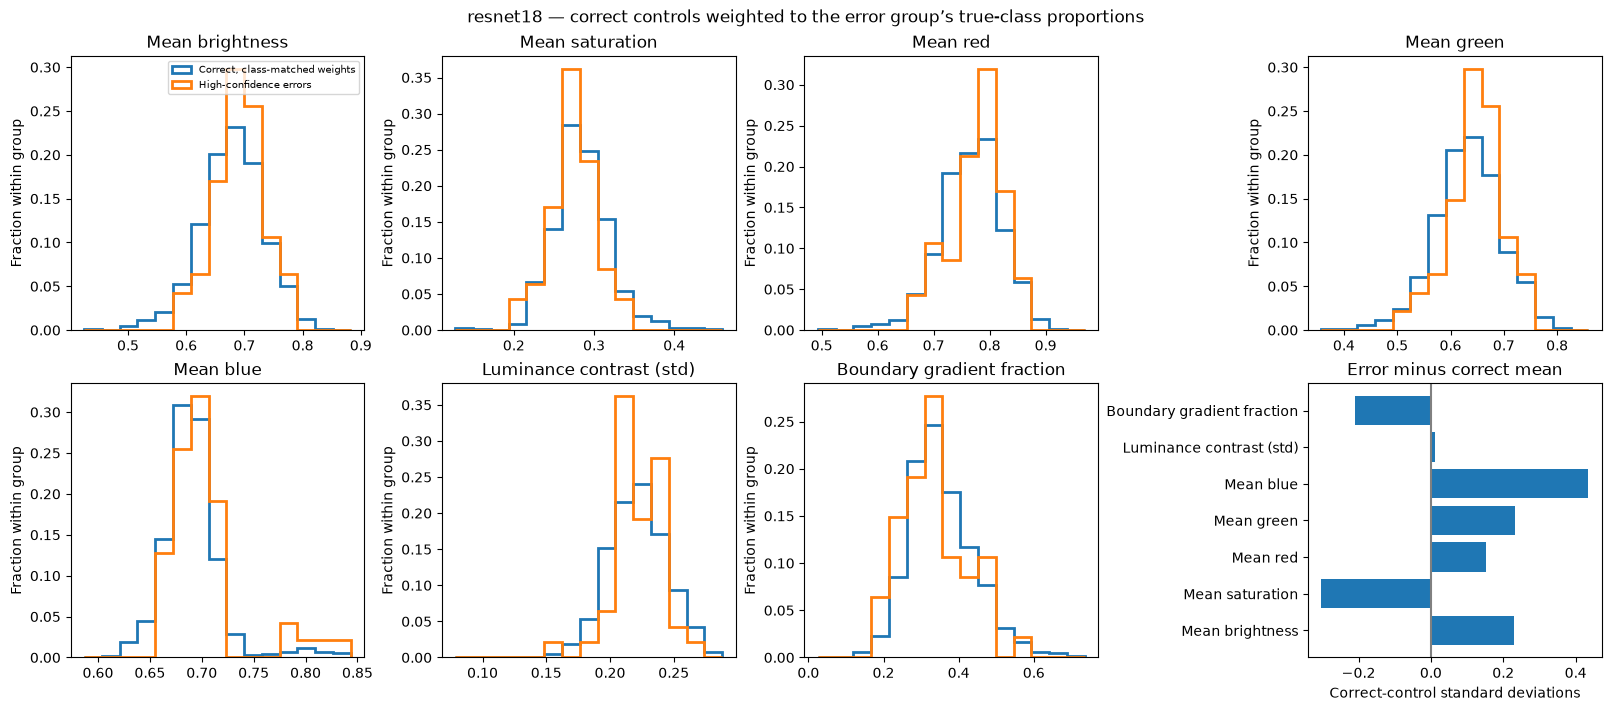

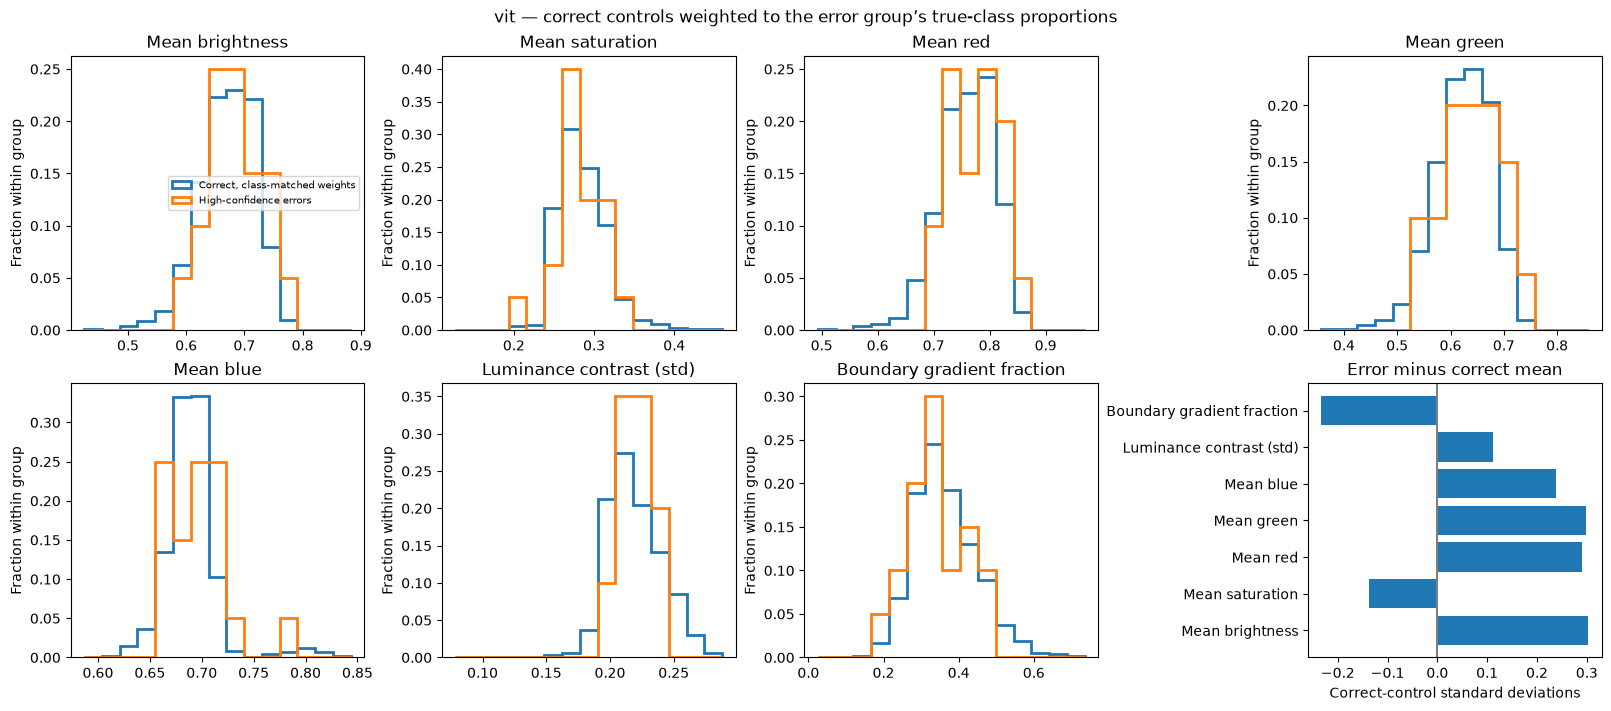

In [11]:
rgb = images.astype(float) / 255
luminance = rgb @ np.array([0.299, 0.587, 0.114])
maximum, minimum = rgb.max(-1), rgb.min(-1)
saturation = np.divide(maximum - minimum, maximum, out=np.zeros_like(maximum), where=maximum > 0)
gy, gx = np.gradient(luminance, axis=(1, 2))
energy = np.hypot(gx, gy)
border = np.ones((28, 28), dtype=bool)
border[4:-4, 4:-4] = False
boundary_energy = energy[:, border].sum(-1) / np.maximum(energy.sum((1, 2)), 1e-12)
features = np.column_stack((luminance.mean((1, 2)), saturation.mean((1, 2)),
                            rgb.mean((1, 2)), luminance.std((1, 2)), boundary_energy))
feature_names = ['Mean brightness', 'Mean saturation', 'Mean red', 'Mean green', 'Mean blue',
                 'Luminance contrast (std)', 'Boundary gradient fraction']
control_weights, feature_effects = [], []
for m, ids in enumerate(error_ids):
    weights = np.zeros(len(labels))
    for c in range(8):
        mask = correct[m] & (labels == c)
        if mask.any() and len(ids):
            weights[mask] = (labels[ids] == c).mean() / mask.sum()
    control_weights.append(weights)
    if not len(ids):
        feature_effects.append(np.full(len(feature_names), np.nan))
        continue
    mean = np.average(features, axis=0, weights=weights)
    std = np.sqrt(np.average((features - mean) ** 2, axis=0, weights=weights))
    effects = (features[ids].mean(0) - mean) / np.maximum(std, 1e-12)
    feature_effects.append(effects)
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), layout='constrained')
    for j, ax in enumerate(axes.flat[:7]):
        edges = np.linspace(features[:, j].min(), features[:, j].max() + 1e-12, 16)
        ax.hist(features[:, j], bins=edges, weights=weights, histtype='step', linewidth=2, label='Correct, class-matched weights')
        ax.hist(features[ids, j], bins=edges, weights=np.full(len(ids), 1 / len(ids)),
                histtype='step', linewidth=2, label='High-confidence errors')
        ax.set(title=feature_names[j], ylabel='Fraction within group')
    axes[0, 0].legend(fontsize=7)
    axes[1, 3].barh(feature_names, effects)
    axes[1, 3].axvline(0, color='gray')
    axes[1, 3].set(title='Error minus correct mean', xlabel='Correct-control standard deviations')
    fig.suptitle(f'{model_names[m]} — correct controls weighted to the error group’s true-class proportions')
    plt.show()

## Similar correctly classified images — nearest raw-RGB RMSE match in the true and predicted classes; class sizes and image alignment affect similarity

resnet18: predicted-class neighbor closer in 55.3% of high-confidence errors


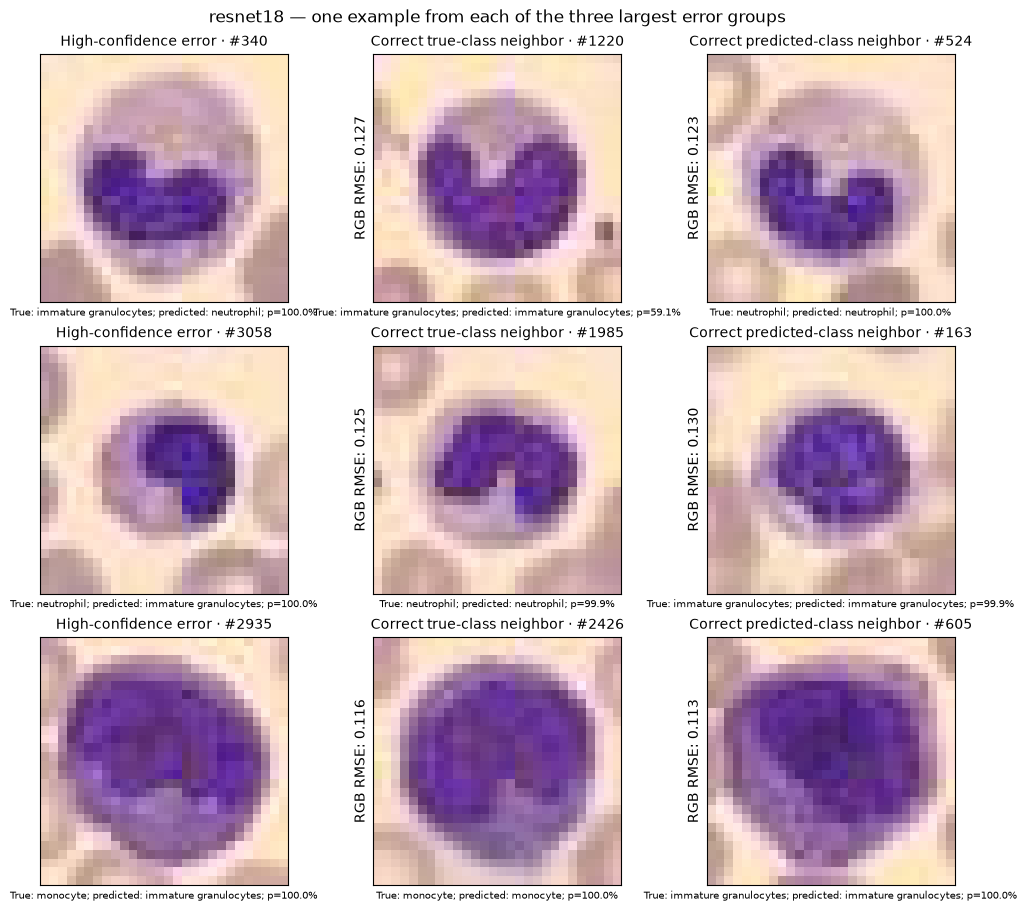

vit: predicted-class neighbor closer in 70.0% of high-confidence errors


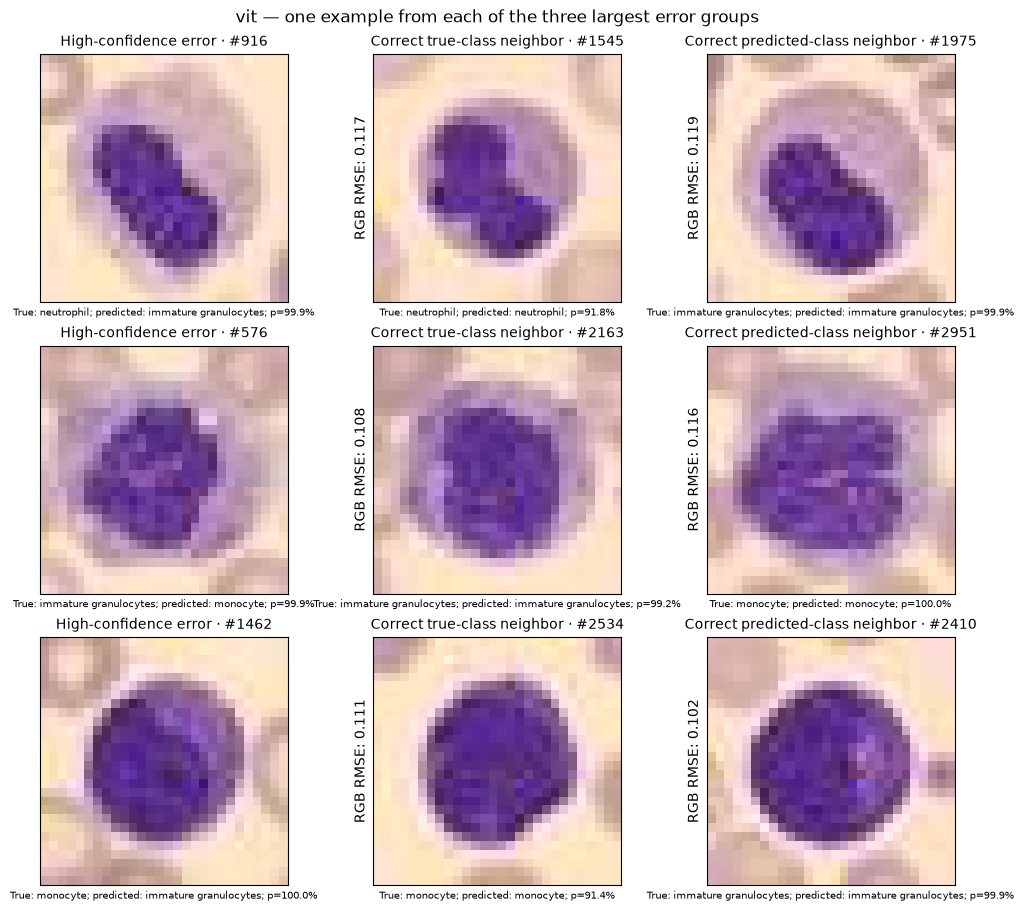

In [12]:
flat = rgb.reshape(len(images), -1).astype(np.float32)
squared = np.square(flat).sum(-1)
neighbor_ids, neighbor_rmse = [], []
for m, ids in enumerate(error_ids):
    distances = np.maximum(squared[:, None] + squared[ids][None, :] - 2 * flat @ flat[ids].T, 0) / flat.shape[1]
    matches, rmses = [], []
    for target in [labels[ids], predicted[m, ids]]:
        allowed = correct[m, :, None] & (labels[:, None] == target[None, :])
        assert allowed.any(axis=0).all(), 'No correct comparison image in a requested class'
        nearest = np.where(allowed, distances, np.inf).argmin(axis=0)
        matches.append(nearest)
        rmses.append(np.sqrt(distances[nearest, np.arange(len(ids))]))
    neighbor_ids.append(np.stack(matches))
    neighbor_rmse.append(np.stack(rmses))
    if not len(example_ids[m]):
        continue
    print(f'{model_names[m]}: predicted-class neighbor closer in {(rmses[1] < rmses[0]).mean():.1%} of high-confidence errors')
    fig, axes = plt.subplots(len(example_ids[m]), 3, figsize=(10, 3 * len(example_ids[m])), squeeze=False, layout='constrained')
    for row, i in enumerate(example_ids[m]):
        pos = np.flatnonzero(ids == i)[0]
        comparison = [i, matches[0][pos], matches[1][pos]]
        titles = ['High-confidence error', 'Correct true-class neighbor', 'Correct predicted-class neighbor']
        for col, (j, title) in enumerate(zip(comparison, titles)):
            ax = axes[row, col]
            ax.imshow(images[j])
            ax.set_title(f'{title} · #{j}', fontsize=10)
            ax.set_xlabel(f'True: {class_names[labels[j]]}; predicted: {class_names[predicted[m, j]]}; p={confidence[m, j]:.1%}', fontsize=7)
            if col:
                ax.set_ylabel(f'RGB RMSE: {rmses[col - 1][pos]:.3f}')
            ax.set_xticks([])
            ax.set_yticks([])
    fig.suptitle(f'{model_names[m]} — one example from each of the three largest error groups')
    plt.show()

## Load models for interventions — no training; saturation and occlusion act on original 28 × 28 RGB images

In [13]:
import torch
from PIL import Image, ImageEnhance
from transformers import ViTForImageClassification, ViTImageProcessor
from models.resnet18.models import ResNet18

torch.manual_seed(42)
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
cnn = ResNet18(in_channels=3, num_classes=8)
cnn.load_state_dict(torch.load('models/resnet18/resnet18_28_1.pth', map_location='cpu', weights_only=True)['net'])
vit = ViTForImageClassification.from_pretrained('models/vit', local_files_only=True)
processor = ViTImageProcessor.from_pretrained('models/vit', local_files_only=True)
models = [cnn.to(device).eval(), vit.to(device).eval()]

@torch.inference_mode()
def intervention_predict(m, batch_images):
    result = []
    for start in range(0, len(batch_images), 32):
        batch = batch_images[start:start + 32]
        if m == 0:
            x = torch.from_numpy(batch.copy()).permute(0, 3, 1, 2).to(device).float()
            logits = models[0]((x / 255 - 0.5) / 0.5)
        else:
            inputs = processor(images=list(batch), return_tensors='pt').to(device)
            logits = models[1](**inputs).logits
        result.append(logits.softmax(-1).cpu().numpy())
    return np.concatenate(result)

for m, ids in enumerate(error_ids):
    if len(ids):
        np.testing.assert_allclose(intervention_predict(m, images[ids]), probabilities[m, ids], atol=1e-5, rtol=1e-4)

## Saturation intervention — errors versus their nearest correctly classified true-class controls; repeated control images are not independent samples

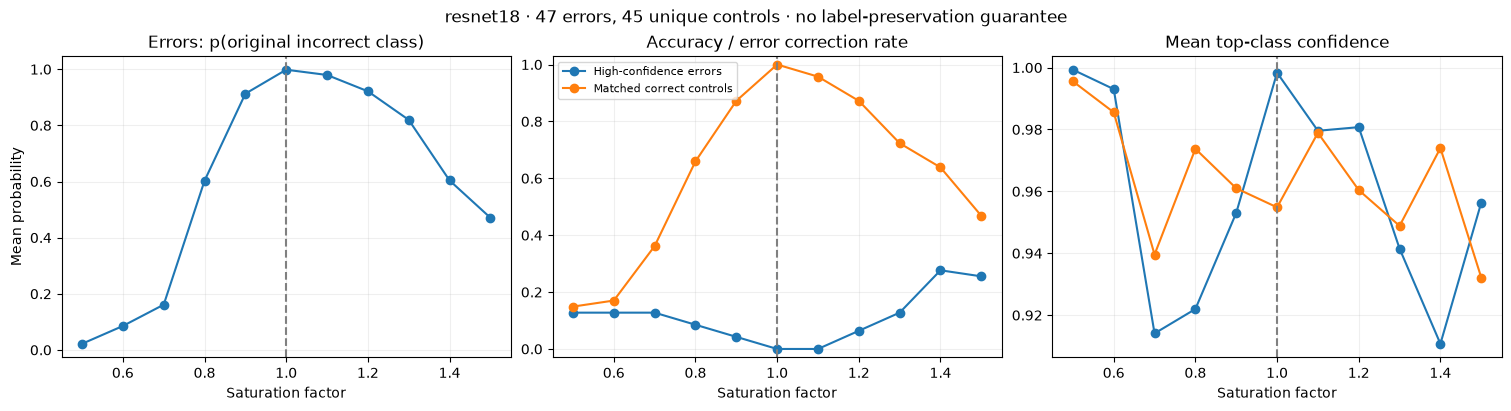

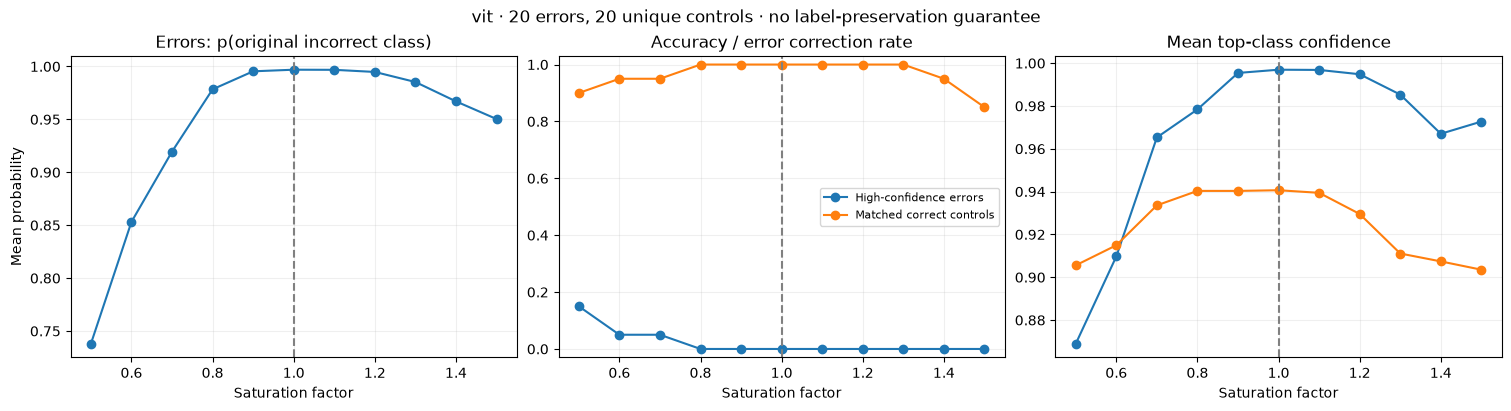

In [14]:
saturation_levels = np.linspace(0.5, 1.5, 11)
saturation_results, saturation_ids = [], []
for m, ids in enumerate(error_ids):
    selected = np.stack((ids, neighbor_ids[m][0]))
    saturation_ids.append(selected)
    if not len(ids):
        saturation_results.append(np.empty((2, 11, 0, 8)))
        continue
    inputs = images[selected.ravel()]
    values = []
    for level in saturation_levels:
        changed = np.stack([np.asarray(ImageEnhance.Color(Image.fromarray(image)).enhance(float(level))) for image in inputs])
        values.append(intervention_predict(m, changed).reshape(2, len(ids), 8))
    p = np.stack(values, axis=1)
    saturation_results.append(p)
    np.testing.assert_allclose(p[:, 5], probabilities[m, selected], atol=1e-5, rtol=1e-4)
    wrong_probability = np.take_along_axis(p[0], predicted[m, ids][None, :, None], axis=-1)[..., 0]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
    axes[0].plot(saturation_levels, wrong_probability.mean(-1), 'o-')
    axes[0].set(title='Errors: p(original incorrect class)', ylabel='Mean probability')
    for role, title in enumerate(['High-confidence errors', 'Matched correct controls']):
        accuracy = (p[role].argmax(-1) == labels[selected[role]]).mean(-1)
        axes[1].plot(saturation_levels, accuracy, 'o-', label=title)
        axes[2].plot(saturation_levels, p[role].max(-1).mean(-1), 'o-', label=title)
    axes[1].set(title='Accuracy / error correction rate', ylim=(-0.03, 1.03))
    axes[2].set(title='Mean top-class confidence')
    for ax in axes:
        ax.axvline(1, color='gray', ls='--')
        ax.set_xlabel('Saturation factor')
        ax.grid(alpha=0.2)
    axes[1].legend(fontsize=8)
    fig.suptitle(f'{model_names[m]} · {len(ids)} errors, {len(np.unique(selected[1]))} unique controls · no label-preservation guarantee')
    plt.show()

## Occlusion — cover every 4 × 4 patch with gray RGB (128, 128, 128); positive drop means reduced probability of the original wrong class

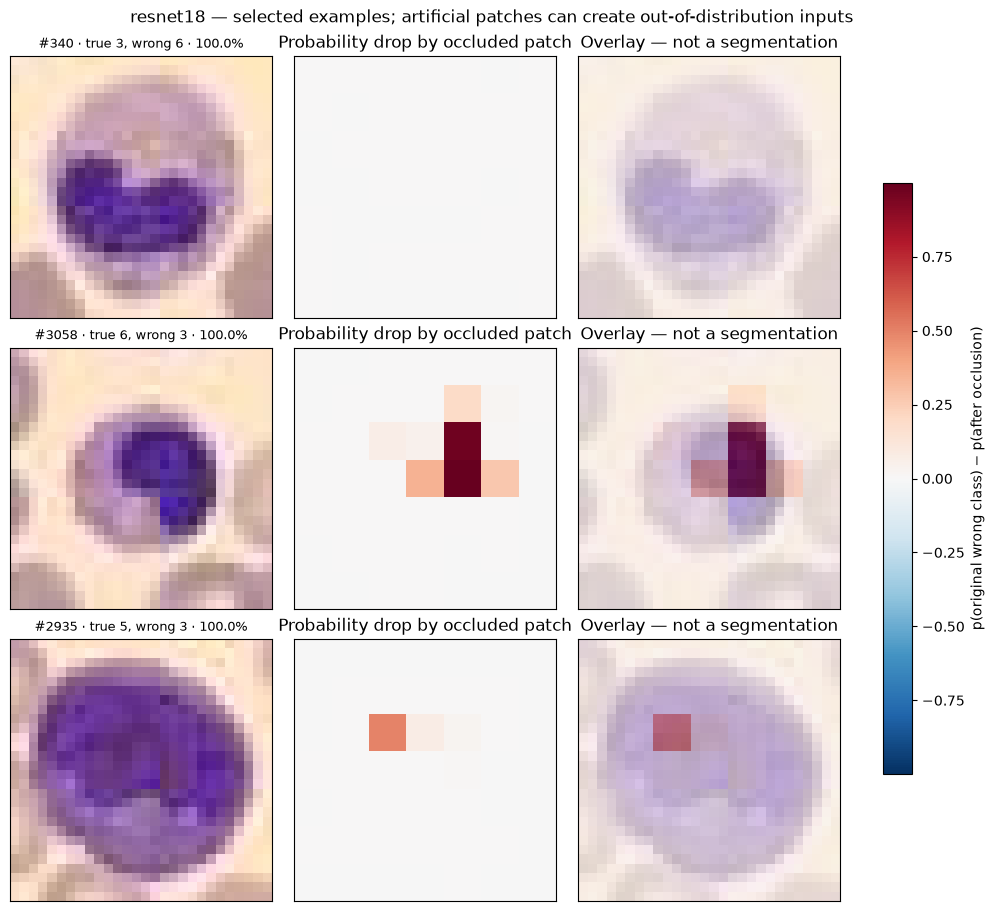

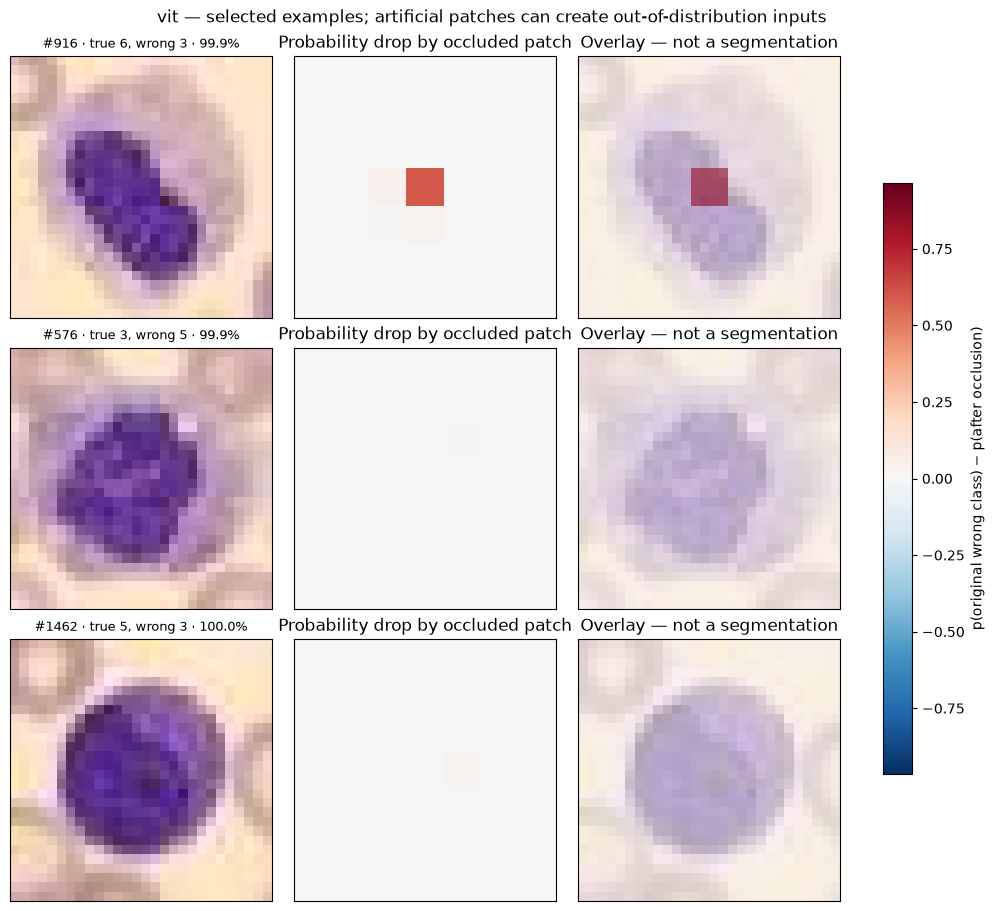

In [15]:
patch_size = 4
positions = np.array([(y, x) for y in range(0, 28, patch_size) for x in range(0, 28, patch_size)])
occlusion_results, occlusion_drop = [], []
for m, ids in enumerate(error_ids):
    if not len(ids):
        occlusion_results.append(np.empty((49, 0, 8)))
        occlusion_drop.append(np.empty((0, 7, 7)))
        continue
    changed = np.repeat(images[ids][None], len(positions), axis=0)
    for j, (y, x) in enumerate(positions):
        changed[j, :, y:y + patch_size, x:x + patch_size] = 128
    p = intervention_predict(m, changed.reshape(-1, 28, 28, 3)).reshape(len(positions), len(ids), 8)
    occlusion_results.append(p)
    target = np.take_along_axis(p, predicted[m, ids][None, :, None], axis=-1)[..., 0]
    maps = (confidence[m, ids][None] - target).T.reshape(len(ids), 7, 7)
    occlusion_drop.append(maps)
    fig, axes = plt.subplots(len(example_ids[m]), 3, figsize=(10, 3 * len(example_ids[m])), squeeze=False, layout='constrained')
    scale = max(np.abs(maps).max(), 0.01)
    for row, i in enumerate(example_ids[m]):
        pos = np.flatnonzero(ids == i)[0]
        heat = np.repeat(np.repeat(maps[pos], patch_size, axis=0), patch_size, axis=1)
        axes[row, 0].imshow(images[i])
        axes[row, 0].set_title(f'#{i} · true {labels[i]}, wrong {predicted[m, i]} · {confidence[m, i]:.1%}', fontsize=9)
        im = axes[row, 1].imshow(maps[pos], cmap='RdBu_r', vmin=-scale, vmax=scale)
        axes[row, 1].set_title('Probability drop by occluded patch')
        axes[row, 2].imshow(images[i])
        axes[row, 2].imshow(heat, cmap='RdBu_r', vmin=-scale, vmax=scale, alpha=0.6)
        axes[row, 2].set_title('Overlay — not a segmentation')
        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])
    fig.colorbar(im, ax=axes, shrink=0.7, label='p(original wrong class) − p(after occlusion)')
    fig.suptitle(f'{model_names[m]} — selected examples; artificial patches can create out-of-distribution inputs')
    plt.show()

## Save all high-confidence-error analysis data — all examples and all intervention probabilities, not just the displayed selections

In [16]:
analysis = dict(shared_indices=shared, union_indices=union, threshold=threshold, split='test',
                model_names=model_names, class_names=class_names, features=features, feature_names=feature_names,
                feature_sample_index=np.arange(len(labels)), true_labels=labels, baseline_probabilities=probabilities,
                control_weights=np.stack(control_weights), feature_effects=np.stack(feature_effects),
                saturation_levels=saturation_levels, occlusion_positions=positions, patch_size=patch_size,
                occlusion_fill_rgb=[128, 128, 128], neighbor_roles=['true_class', 'predicted_class'],
                saturation_roles=['high_confidence_errors', 'matched_correct_controls'])
for m, name in enumerate(model_names):
    for key, value in dict(error_ids=error_ids[m], confusion=confusions[m], selected_examples=example_ids[m],
                           neighbor_ids=neighbor_ids[m], neighbor_rmse=neighbor_rmse[m],
                           saturation_ids=saturation_ids[m], saturation_probabilities=saturation_results[m],
                           occlusion_probabilities=occlusion_results[m], occlusion_drop=occlusion_drop[m]).items():
        analysis[f'{name}_{key}'] = value
    if len(error_ids[m]):
        j = np.abs(feature_effects[m]).argmax()
        corrections = (saturation_results[m][0].argmax(-1) == labels[error_ids[m]]).sum(-1)
        print(f'{name}: largest descriptive feature shift: {feature_names[j]} ({feature_effects[m][j]:+.2f} control SD)')
        control_errors = (saturation_results[m][1].argmax(-1) != labels[saturation_ids[m][1]]).sum(-1)
        print('Saturation factor / corrected errors / newly wrong matched control pairs:', list(zip(saturation_levels.round(2).tolist(), corrections.tolist(), control_errors.tolist())))
        involved = ((labels[error_ids[m]] == 3) | (predicted[m, error_ids[m]] == 3)).sum()
        print(f'{name}: immature granulocytes occur on either side of {involved}/{len(error_ids[m])} error pairs')
        print(f'{name}: mean largest wrong-class probability drop per image under occlusion: {occlusion_drop[m].max((1, 2)).mean():.3f}')
path = Path('predictions/high_confidence_error_analysis.npz')
np.savez_compressed(path, **analysis)
print(path)
print('Hypotheses to investigate: appearance/staining sensitivity in a subset of errors; visual ambiguity around immature-granulocyte confusions. Saturation can also damage correct controls, so correction counts alone are not evidence of improvement.')
print('Exploratory only: correlated color features, class composition, pixel alignment, unequal neighbor-pool sizes and artificial interventions prevent causal or biological conclusions. Validate hypotheses on new images, not these selected errors.')

resnet18: largest descriptive feature shift: Mean blue (+0.44 control SD)
Saturation factor / corrected errors / newly wrong matched control pairs: [(0.5, 6, 40), (0.6, 6, 39), (0.7, 6, 30), (0.8, 4, 16), (0.9, 2, 6), (1.0, 0, 0), (1.1, 0, 2), (1.2, 3, 6), (1.3, 6, 13), (1.4, 13, 17), (1.5, 12, 25)]
resnet18: immature granulocytes occur on either side of 39/47 error pairs
resnet18: mean largest wrong-class probability drop per image under occlusion: 0.607
vit: largest descriptive feature shift: Mean brightness (+0.30 control SD)
Saturation factor / corrected errors / newly wrong matched control pairs: [(0.5, 3, 2), (0.6, 1, 1), (0.7, 1, 1), (0.8, 0, 0), (0.9, 0, 0), (1.0, 0, 0), (1.1, 0, 0), (1.2, 0, 0), (1.3, 0, 0), (1.4, 0, 1), (1.5, 0, 3)]
vit: immature granulocytes occur on either side of 18/20 error pairs
vit: mean largest wrong-class probability drop per image under occlusion: 0.268
predictions\high_confidence_error_analysis.npz
Hypotheses to investigate: appearance/staining sens